# Redes do PPA: termos, programas, oferta e demanda, genealogia

Rodada de 13/11/2026, depois da reunião com o Dominik. Olha **todos os programas** dos 6 PPAs (529), não só os 42 pares de política industrial, com quatro redes:

1. **Termos:** lemas ligados por aparecerem na mesma frase.
2. **Programas:** programas do mesmo PPA ligados pelo que **dizem** (objetivo + justificativa) e pelo que **fazem** (nomes das subações).
3. **Oferta e demanda:** área do órgão responsável (quem executa) → categoria de público-alvo (quem recebe), com o valor orçado.
4. **Genealogia:** cada programa ligado ao do PPA seguinte pelas subações e pelo texto que herdou.

A ideia de fundo é um **"espaço de políticas"** análogo ao espaço de produtos da complexidade econômica: a proximidade entre termos usa a mesma forma da proximidade entre produtos (mínimo das probabilidades condicionais) e a "densidade de política industrial" de um programa segue a lógica da densidade de um produto em torno do que o país já faz.

**Regras com aprovação preliminar do Andrey** (13/11/2026), todas em `scripts/redes_regras.py`; funções em `scripts/redes.py`. Medida: contagens, sem TF-IDF. Afirmação que não sai dos documentos: [verificar].

In [ ]:
# No Google Colab: baixa o repositório com os resultados. No computador local, não faz nada.
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/tcc"):
        !git clone -q https://github.com/andreydeps/tcc-politica-industrial-sc.git /content/tcc
    %cd /content/tcc

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
S = RAIZ / "saidas"
sys.path.insert(0, str(RAIZ / "scripts"))
from ppa_inteiro_analise import carregar, PER
import redes_regras as R
from redes import rede_termos, sensibilidade_termos, rede_programas, rede_oferta_demanda, genealogia

p, s, f = carregar()
print(f"{len(p)} programas | {len(f)} frases | {len(s)} subações")

def fig(nome, largura=900):
    display(Image(filename=str(S / nome), width=largura))

def tabela(df, casas=2, p_cols=()):
    num = lambda k: (lambda v: "" if pd.isna(v) else f"{v:,.{k}f}".replace(",", "X").replace(".", ",").replace("X", "."))
    fmt = {c: num(0 if pd.api.types.is_integer_dtype(df[c]) else 3 if c in p_cols else casas)
           for c in df.select_dtypes("number").columns}
    display(df.style.hide(axis="index").format(fmt).set_properties(**{"text-align": "left"}))

529 programas | 1382 frases | 18687 subações


## 1. Rede de termos

Unidade: frase de objetivo ou justificativa (1.382 frases). Lema entra se aparece em pelo menos **4 frases**; ligação se dois lemas aparecem juntos em pelo menos **2 frases**. Peso da ligação: **proximidade** phi = frases com os dois / max(frases com um, frases com o outro), a mesma forma da proximidade do espaço de produtos (não infla palavras muito frequentes). Comunidades: Louvain (semente 42). Estabilidade: outras sementes e 50 reamostragens de frases (ARI = 1 é partição idêntica; 0 é acaso).

In [2]:
info, comunidades, estab, alvos, metades = rede_termos(f, p)
print(info)
tabela(estab)

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\rede_termos.png


figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\rede_termos_vizinhancas.png


{'lemas na rede': 859, 'ligações': 18912, 'comunidades': 19, 'frases': 1382}


teste,ARI médio,ARI mínimo
outras 20 sementes do Louvain,"0,61","0,48"
50 reamostragens de frases,"0,23","0,17"


Os mesmos números com outros limiares (para ver se o problema é a regra escolhida):

In [3]:
tabela(sensibilidade_termos(f))

mín. frases do lema,mín. frases juntas,phi mínimo,lemas,ligações,comunidades,ARI entre sementes,ARI nas reamostragens
4,2,"0,00",859,18.912,19,"0,60","0,22"
8,2,"0,00",475,13.177,12,"0,54","0,25"
8,3,"0,00",475,7.970,13,"0,62","0,23"
12,3,"0,00",324,6.171,12,"0,54","0,24"
8,2,"0,15",475,2.167,15,"0,68","0,23"
12,3,"0,15",321,1.154,14,"0,70","0,24"
15,3,"0,20",226,388,20,"0,90","0,26"


**As comunidades não se sustentam.** Mudam pouco com a semente (ARI 0,61), mas quase por inteiro quando as frases são reamostradas (ARI 0,23), e nenhum limiar testado melhora isso (0,22 a 0,26). É o mesmo diagnóstico do LDA: com textos curtos, não há "campos semânticos" globais estáveis no PPA. Por isso a figura abaixo pinta os **temas aprovados**, não as comunidades, e a leitura fica nas **vizinhanças** de cada termo, que podem ser testadas uma a uma.

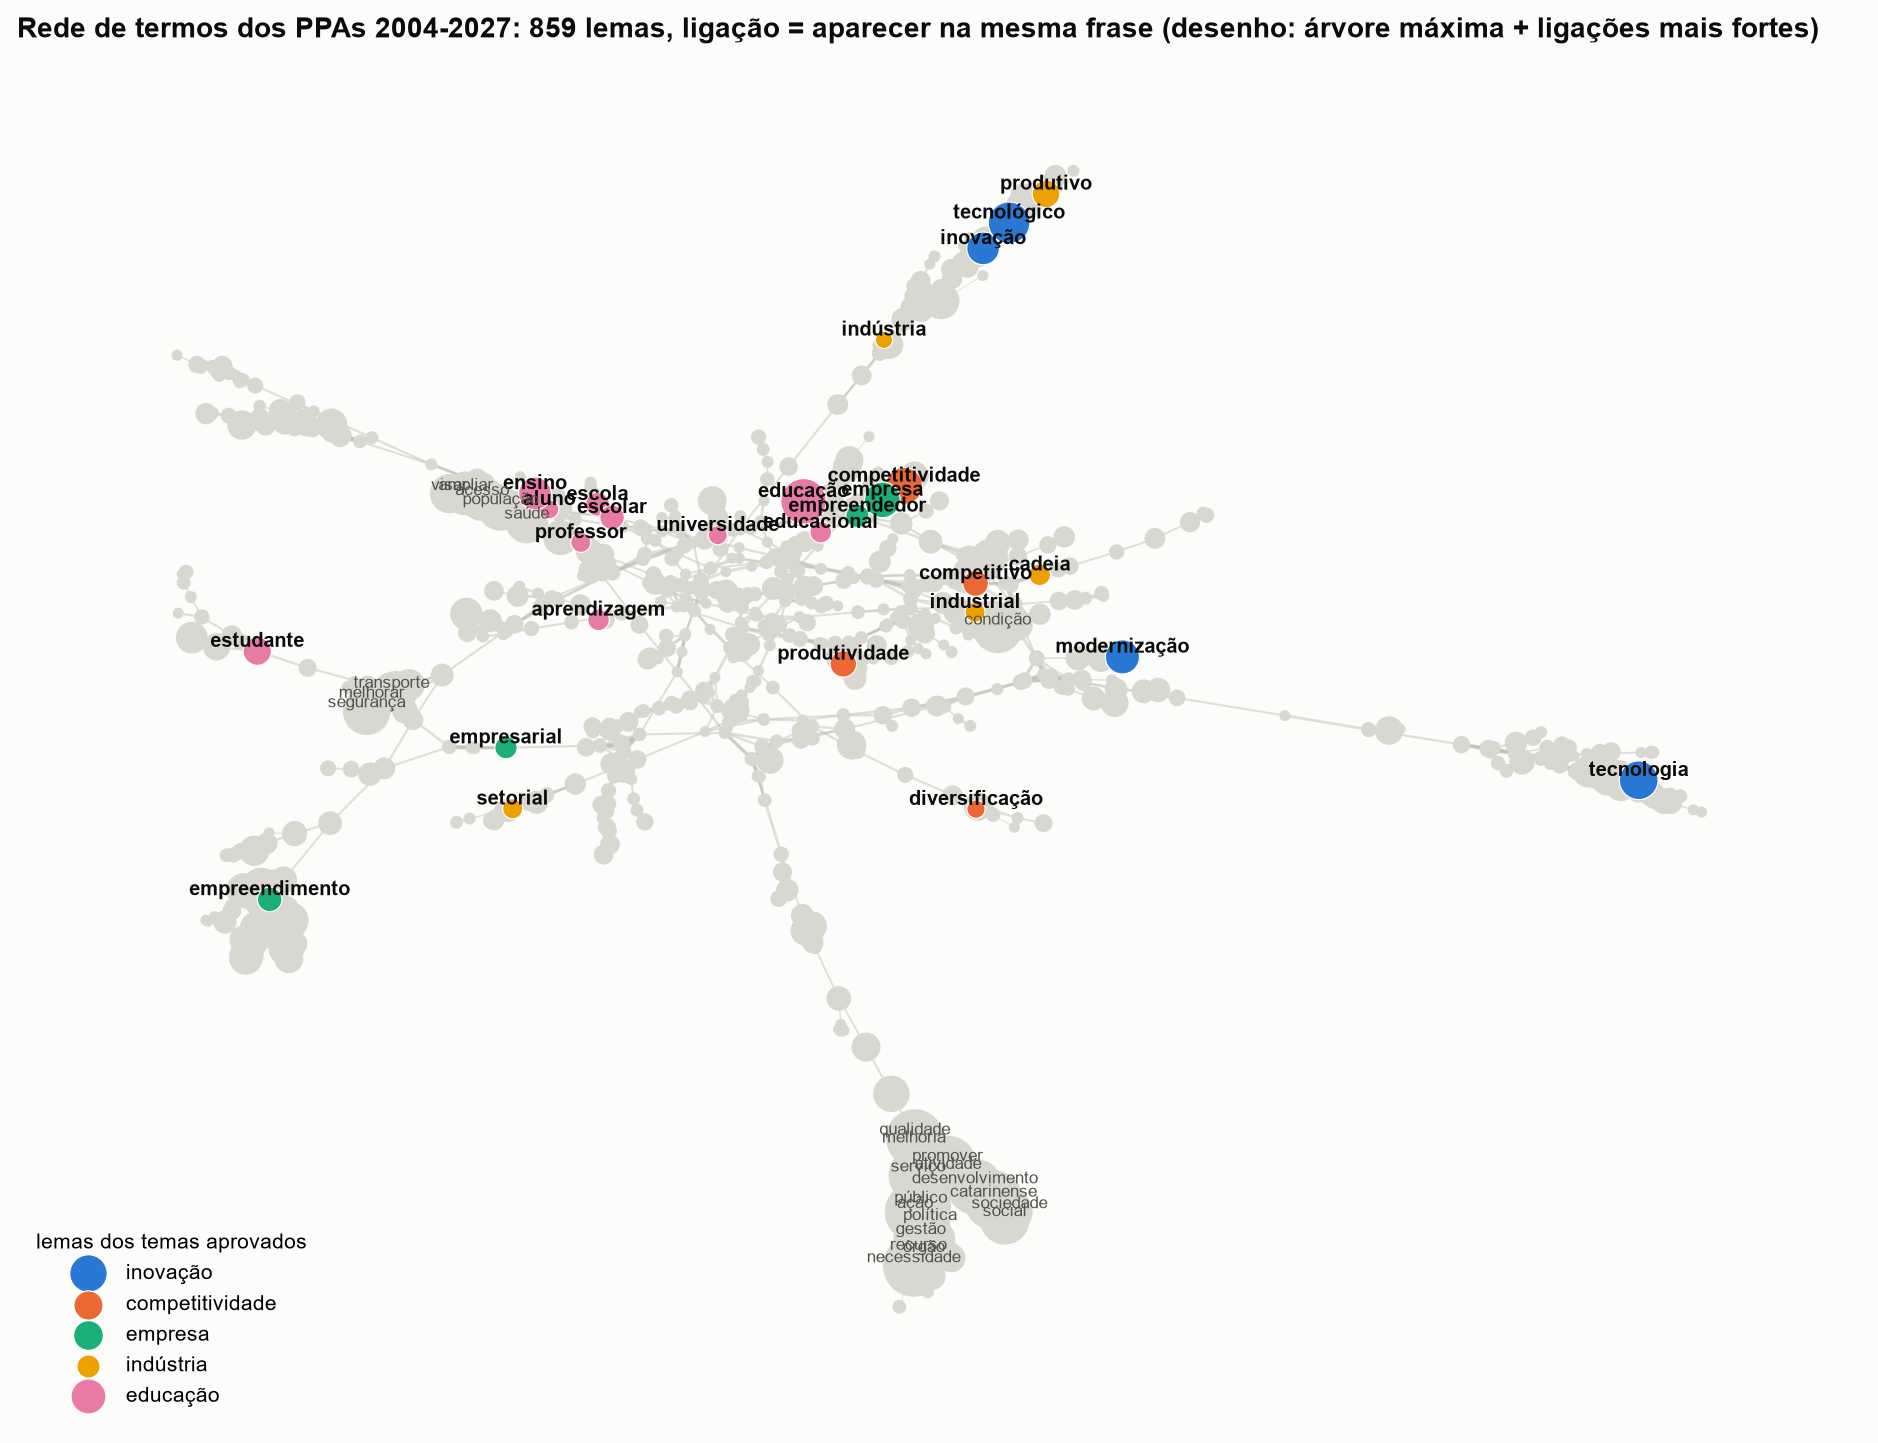

alvo,frases,grau,vizinhos mais próximos (phi),co-agrupado com os 5 vizinhos (% das reamostragens)
inovação,27,88,"tecnológico (0.32), incentivar (0.26), empresa (0.24), base (0.22), nacional (0.20), ambiente (0.19)","41,2"
competitividade,36,106,"empresa (0.25), produtivo (0.25), economia (0.22), fomentar (0.22), bem (0.19), inovação (0.19)","40,4"
tecnologia,40,121,"informação (0.20), tecnológico (0.19), criação (0.17), inovação (0.17), ampliação (0.15), cidadão (0.13)","48,0"
empresa,33,104,"empreendedor (0.30), pequeno (0.30), competitividade (0.25), inovação (0.24), criação (0.21), existente (0.21)","64,8"
indústria,4,16,"gás (0.20), comércio (0.17), segmento (0.12), disponibilizar (0.11), mercado (0.09), competitividade (0.08)","51,2"
tecnológico,47,159,"inovação (0.32), base (0.26), necessário (0.21), humano (0.20), científico (0.19), conhecimento (0.19)","46,4"
produtivo,18,63,"base (0.29), competitividade (0.25), criação (0.25), empreendedor (0.22), ligar (0.22), negócio (0.22)","58,4"
emprego,21,51,"renda (0.36), geração (0.22), turístico (0.19), qualificar (0.18), ampliar (0.13), produto (0.12)","38,0"


In [4]:
fig("rede_termos.png", 950)
tabela(alvos, 1)

Vizinhos de cada termo nas duas metades do período, com a % das 200 reamostragens de frases em que o vizinho continua entre os 6 mais próximos:

alvo,metade,frases,vizinhos (phi; frases juntas; % das reamostragens no top 6)
inovação,2004-2015,9,"tecnológico (0.50; 7; 88%), base (0.36; 4; 49%), fomentar (0.33; 3; 38%), competitividade (0.25; 3; 19%), produtivo (0.22; 2; 16%), princípio (0.22; 2; 22%)"
competitividade,2004-2015,12,"bem (0.33; 4; 67%), produtivo (0.25; 3; 54%), inovação (0.25; 3; 46%), base (0.25; 3; 35%), tecnológico (0.21; 3; 36%), socioambiental (0.17; 2; 31%)"
tecnologia,2004-2015,24,"informação (0.24; 7; 71%), oportunidade (0.17; 4; 38%), empresarial (0.17; 4; 34%), criação (0.17; 4; 34%), ampliação (0.17; 4; 32%), desenvolvimento (0.13; 8; 14%)"
empresa,2004-2015,14,"pequeno (0.36; 5; 76%), tecnológico (0.29; 4; 59%), privado (0.21; 3; 41%), inovação (0.21; 3; 34%), empreendedor (0.21; 3; 36%), criação (0.21; 3; 37%)"
indústria,2004-2015,1,
tecnológico,2004-2015,14,"inovação (0.50; 7; 96%), base (0.50; 7; 86%), produtivo (0.29; 4; 46%), empresa (0.29; 4; 36%), fomentar (0.21; 3; 18%), empresarial (0.21; 3; 24%)"
produtivo,2004-2015,9,"fomentar (0.44; 4; 62%), base (0.36; 4; 46%), tecnológico (0.29; 4; 34%), competitividade (0.25; 3; 21%), sustentabilidade (0.22; 2; 28%), padrão (0.22; 2; 32%)"
emprego,2004-2015,12,"renda (0.36; 9; 93%), geração (0.26; 5; 70%), êxodo (0.17; 2; 44%), turístico (0.17; 2; 30%), possuir (0.17; 2; 36%), incrementar (0.17; 2; 30%)"
inovação,2016-2027,18,"tecnologia (0.28; 5; 58%), incentivar (0.28; 5; 64%), empresa (0.26; 5; 49%), tecnológico (0.24; 8; 56%), setor (0.22; 4; 50%), regional (0.22; 4; 38%)"
competitividade,2016-2027,24,"empresa (0.29; 7; 72%), economia (0.26; 7; 56%), produtivo (0.25; 6; 63%), aumento (0.25; 6; 50%), econômico (0.24; 8; 50%), fomentar (0.23; 6; 47%)"


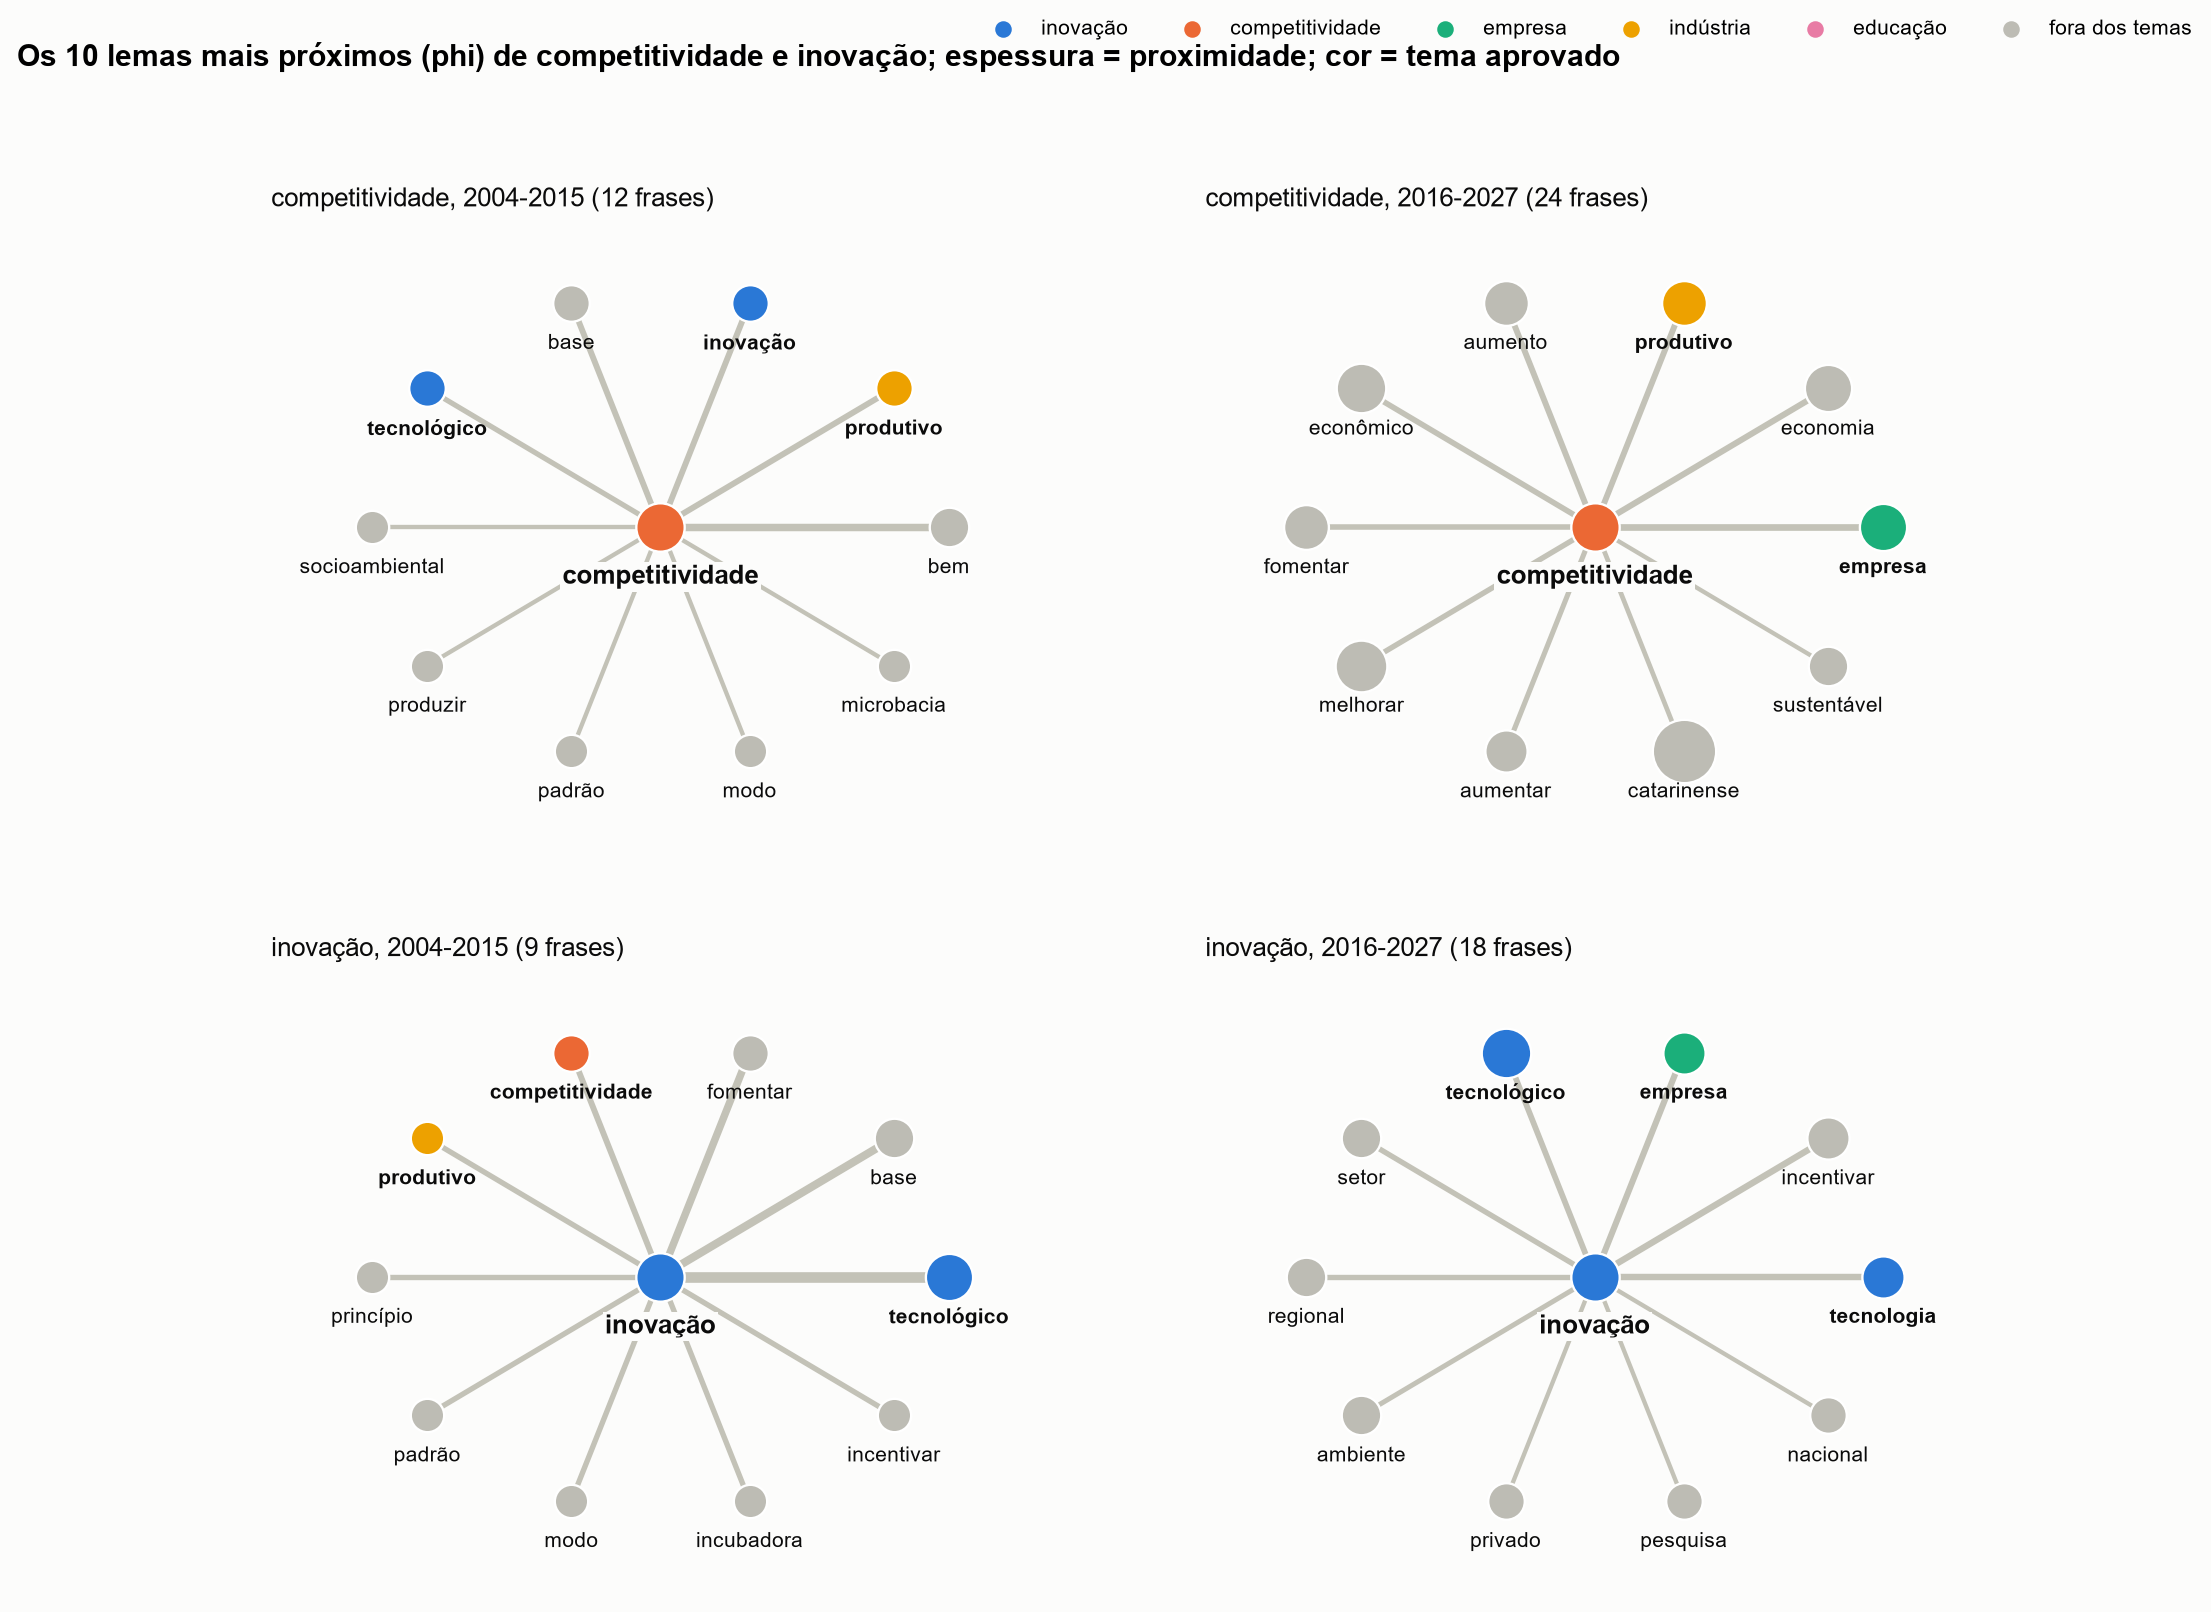

In [5]:
with pd.option_context("display.max_colwidth", None):
    display(metades.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))
fig("rede_termos_vizinhancas.png", 900)

**Leitura:** **competitividade muda de vizinhança.** Em 2004-2015 anda com produtivo, inovação, base e tecnológico (vocabulário de base tecnológica e produção); em 2016-2027 anda com **empresa** (fica entre os 6 mais próximos em 72% das reamostragens), economia, produtivo, aumento e econômico, e **inovação sai do top 6**. Inovação fica ligada a tecnológico nas duas metades, mas em 2016-2027 também a incentivar, empresa, setor e regional. "Tecnológico" em 2016-2027 vira fórmula administrativa (humano, material, financeiro: "recursos humanos, materiais, tecnológicos e financeiros"). "Tecnologia" fica longe de inovação na rede, perto de informação (tecnologia da informação). "Indústria" tem 4 frases em 20 anos, quase todas sobre gás natural. Contagens pequenas: 9 a 33 frases por termo e metade.

## 2. Rede de programas: o que dizem x o que fazem

Em cada PPA, dois vetores de contagem por programa: lemas de objetivo + justificativa (**o que dizem**) e lemas dos nomes das subações, sem repetir nome igual (**o que fazem**). Lemas presentes em mais de **20% dos programas do PPA** saem como palavras de formato. Similaridade: cosseno. Rede: cada programa ligado aos **3 mais parecidos** (cosseno de pelo menos 0,10).

- **Homofilia:** similaridade média entre selecionados dividida pela similaridade média entre selecionados e os demais; p por permutação dos rótulos (2.000).
- **Mantel:** correlação de Spearman entre as duas matrizes de similaridade (o que dizem x o que fazem), p por permutação dos programas.
- **Densidade de política industrial** de cada programa: soma da similaridade com os selecionados / soma da similaridade com todos (a densidade da complexidade econômica).

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\rede_programas.png


periodo,camada,programas,ligações,homofilia (dentro/entre),p homofilia,comunidades,comunidades com selecionados,selecionados na comunidade principal
2004-2007,texto (o que dizem),"118,00","240,00","1,42","0,094","12,00","4,00","4,00"
2004-2007,subações (o que fazem),"118,00","208,00","1,80","0,064","28,00","7,00","2,00"
2004-2007,"correlação entre as camadas (Mantel, Spearman)",,,"0,04","0,054",,,
2008-2011,texto (o que dizem),"65,00","128,00","2,11","0,065","9,00","3,00","2,00"
2008-2011,subações (o que fazem),"65,00","117,00","3,06","0,018","11,00","2,00","3,00"
2008-2011,"correlação entre as camadas (Mantel, Spearman)",,,"0,22","0,000",,,
2012-2015,texto (o que dizem),"85,00","170,00","2,93","0,005","12,00","3,00","6,00"
2012-2015,subações (o que fazem),"85,00","174,00","2,95","0,002","9,00","4,00","5,00"
2012-2015,"correlação entre as camadas (Mantel, Spearman)",,,"0,21","0,000",,,
2016-2019,texto (o que dizem),"87,00","175,00","3,37","0,006","9,00","2,00","6,00"


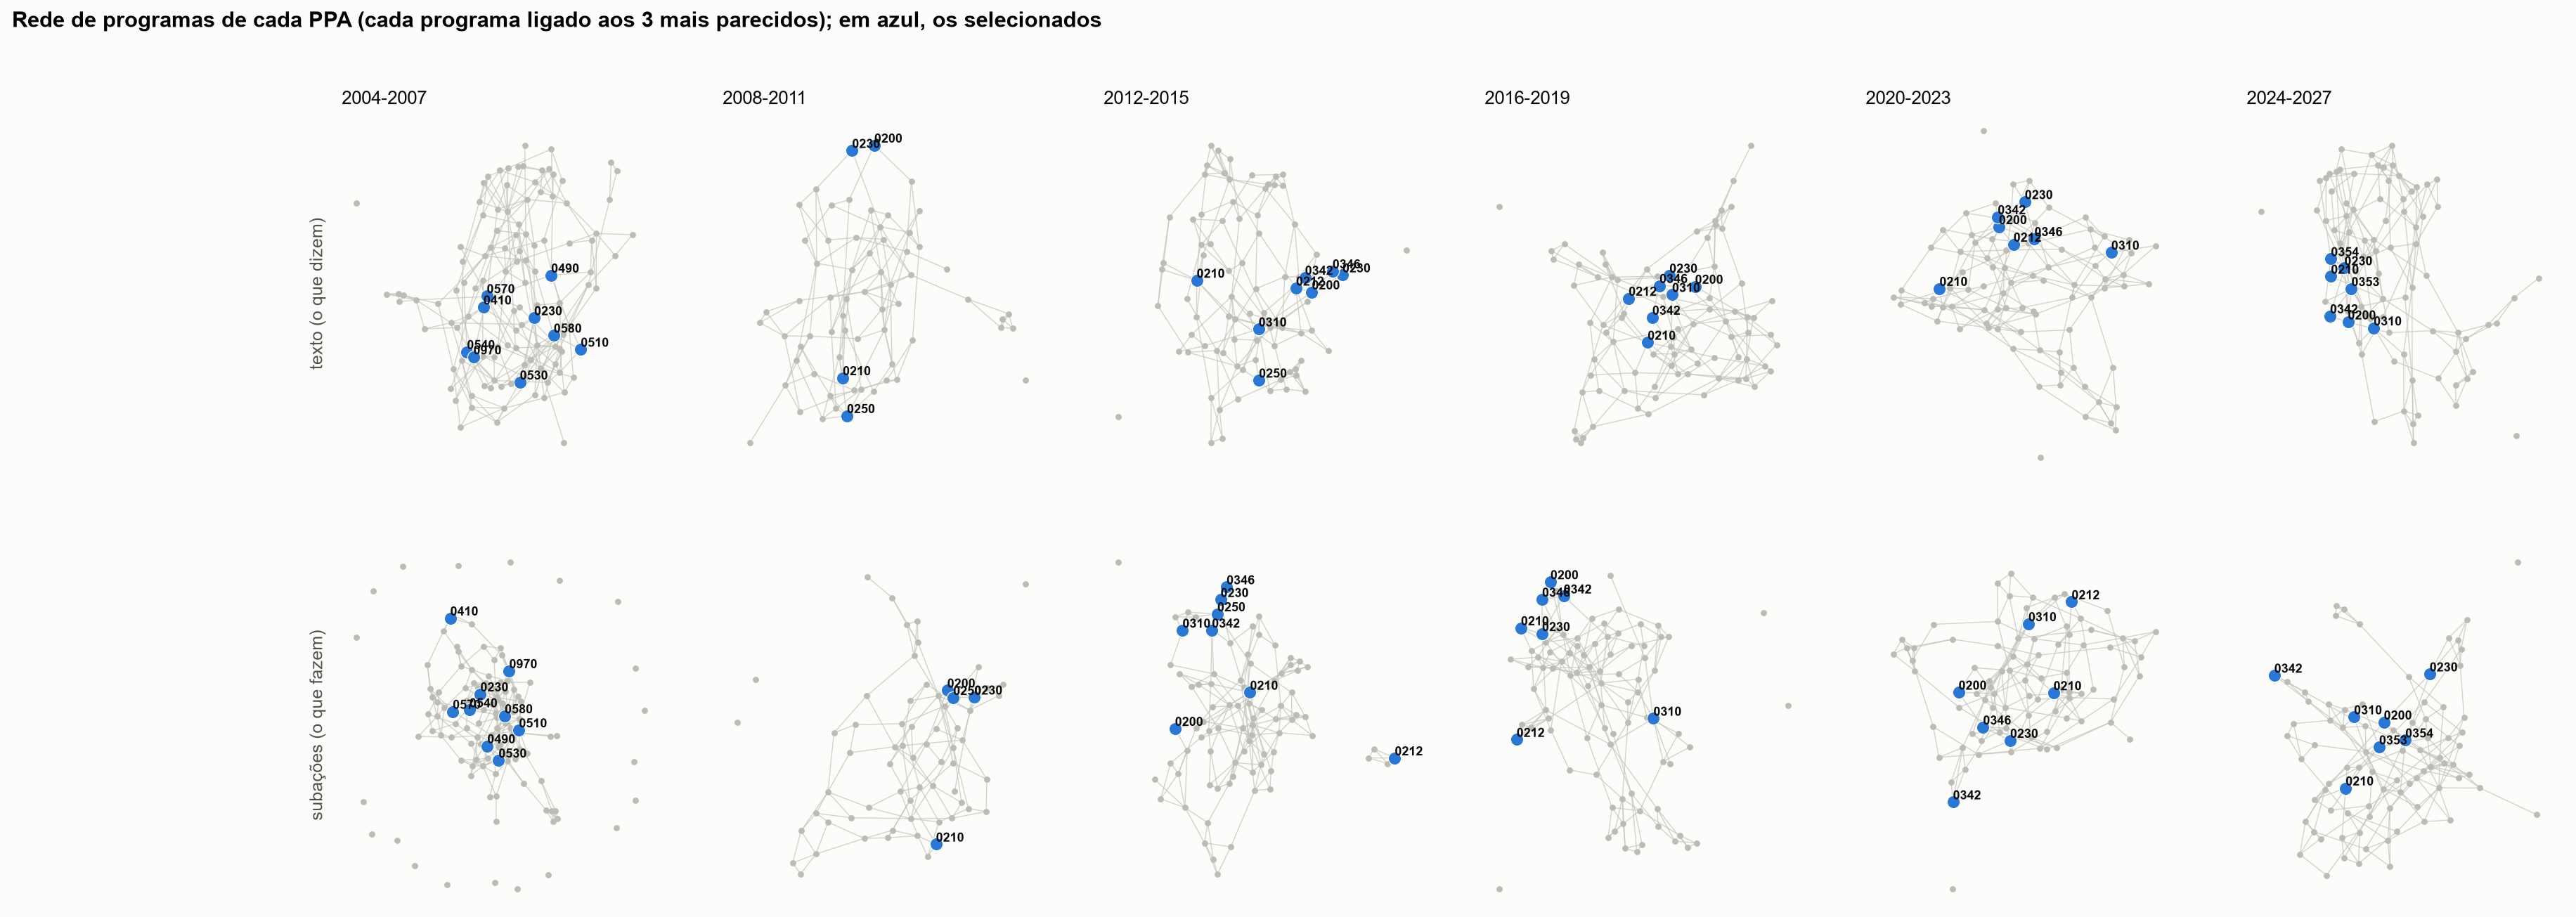

In [6]:
resumo_prog, densidade, comunidades_prog = rede_programas(p, s)
tabela(resumo_prog.drop(columns=["palavras de formato retiradas"]), 2, p_cols=("p homofilia",))
fig("rede_programas.png", 1100)

Comunidade (Louvain) que reúne mais selecionados, em cada PPA e camada (* = selecionado):

In [7]:
with pd.option_context("display.max_colwidth", None):
    display(comunidades_prog.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))

periodo,camada,comunidade principal da política industrial
2004-2007,texto (o que dizem),"0200, 0210, 0215, 0218, 0225, 0226, 0234, 0240, 0250, 0255, 0320, 0373, 0490*, 0498, 0502, 0508, 0540*, 0570*, 0619, 0627, 0845, 0970*"
2004-2007,subações (o que fazem),"0170, 0200, 0250, 0480, 0490*, 0505, 0508, 0530*, 0619, 0670, 0740, 0850, 0860, 0900, 0940"
2008-2011,texto (o que dizem),"0120, 0130, 0140, 0160, 0180, 0200*, 0230*, 0310, 0940"
2008-2011,subações (o que fazem),"0115, 0200*, 0220, 0230*, 0240, 0250*, 0640, 0905"
2012-2015,texto (o que dizem),"0101, 0200*, 0212*, 0230*, 0310*, 0315, 0320, 0342*, 0346*, 0350, 0360, 0365, 0720, 0187"
2012-2015,subações (o que fazem),"0220, 0230*, 0250*, 0300, 0310*, 0315, 0320, 0342*, 0346*, 0540, 0622, 0730, 0440"
2016-2019,texto (o que dizem),"0200*, 0204, 0212*, 0230*, 0250, 0300, 0310*, 0315, 0342*, 0346*, 0540, 0650, 0160, 0180, 0186"
2016-2019,subações (o que fazem),"0230*, 0342*, 0346*, 0630"
2020-2023,texto (o que dizem),"0101, 0105, 0200*, 0212*, 0230*, 0300, 0320, 0340, 0342*, 0346*, 0348, 0635, 0922"
2020-2023,subações (o que fazem),"0830, 0870, 0210*, 0212*, 0340, 0343, 0348, 0520, 0610, 0623, 0624, 0626, 0701, 0702, 0703, 0835, 0845, 0440, 0921"


Programas fora da lista com maior densidade de política industrial (3 por PPA e camada) e a probabilidade do classificador:

In [8]:
camadas = ["texto (o que dizem)", "subações (o que fazem)"]
top = []
for q in PER:
    d = densidade[(densidade.periodo == q) & (densidade.selecionado == 0)]
    for cam in camadas:
        for r in d.nlargest(3, cam).itertuples():
            top.append({"periodo": q, "camada": cam, "codigo": r.codigo, "nome": r.nome[:60],
                        "densidade": d.loc[r.Index, cam],
                        "prob. classificador": r.prob_classificador})
tabela(pd.DataFrame(top), 2)
fora = densidade[densidade.selecionado == 0]
from scipy.stats import spearmanr
for cam in camadas:
    rho = spearmanr(fora[cam], fora["prob_classificador"], nan_policy="omit")[0]
    print(f"Spearman densidade ({cam}) x classificador, programas fora da lista: {rho:.2f}")

periodo,camada,codigo,nome,densidade,prob. classificador
2004-2007,texto (o que dizem),0226,Leite e Carne em Pastagem Melhorada,"0,20","0,40"
2004-2007,texto (o que dizem),0498,Gestão da Fundação UDESC,"0,19","0,13"
2004-2007,texto (o que dizem),0373,Proteção à Criança e ao Adolescente,"0,19","0,11"
2004-2007,subações (o que fazem),0360,Gestão da Política Habitacional,"0,45","0,05"
2004-2007,subações (o que fazem),0390,Assistência à Familia,"0,32","0,60"
2004-2007,subações (o que fazem),0215,Desenvolvimento Florestal - Florestar,"0,28","0,05"
2008-2011,texto (o que dizem),0100,ProPav Rural,"0,20","0,05"
2008-2011,texto (o que dizem),0310,Agronegócio Competitivo,"0,13","0,85"
2008-2011,texto (o que dizem),0820,Comunicação do Poder Legislativo,"0,13","0,05"
2008-2011,subações (o que fazem),0220,Governança Eletrônica,"0,18","0,11"


Spearman densidade (texto (o que dizem)) x classificador, programas fora da lista: 0.46
Spearman densidade (subações (o que fazem)) x classificador, programas fora da lista: 0.22


**Leitura:** **no texto, a política industrial é um bloco**: os selecionados são 2,8 a 3,4 vezes mais parecidos entre si do que com o resto do plano de 2012-2015 em diante (p de 0,002 a 0,006); em 2004-2011 a razão é menor e não significativa. **Nas subações, o bloco existe até 2019 e se desfaz depois**: razão de 2,95 a 3,06 em 2008-2019 (p até 0,02), contra 1,6 e 1,8 em 2020-2027 (p 0,08 e 0,03). Os programas continuam falando parecido, mas passam a fazer coisas diferentes (crédito no BADESC, bolsas na CT&I, folha da EPAGRI, emendas no 0210). A correlação entre o que os programas dizem e o que fazem é **baixa** (Mantel de 0,15 a 0,22 de 2008 em diante; 0,04 em 2004-2007). Os programas fora da lista mais "densos" em política industrial repetem candidatos já discutidos (0530 Pró-Emprego e Renda, 0204 Missões Internacionais) e trazem outros (0211 Metrologia pelo texto em 2020-2027; 0343 Economia Solidária pelas subações). A densidade pelo texto concorda com o classificador (Spearman 0,46), pelas subações bem menos (0,22).

## 3. Oferta e demanda

Oferta: área do órgão responsável pelo programa (regras em `AREAS`). Demanda: categoria do público-alvo, agora com as 4 categorias a mais (setor público, estudantes e escolas, grupos vulneráveis, sem definição). **Precedência:** "sociedade em geral" só conta se nenhuma outra categoria casar, e micro e pequenas empresas substitui empresas. **Exceção explícita:** "Cidadãos, investidores, turistas e consumidores" (comunicação institucional) vai para sociedade em geral. Peso: valor das subações sem pessoal e emendas, em % do PPA (também sem pessoal e emendas); programa com mais de um público tem o valor dividido em partes iguais.

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\rede_oferta_demanda.png


**Demanda: % do valor do PPA por público**

categoria,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
setor público,"35,83","68,22","54,72","68,06","50,84","51,57"
sociedade em geral,"41,82","25,73","28,52","22,54","34,43","31,84"
estudantes e escolas,"6,43","0,80","9,76","3,97","7,85","10,80"
grupos vulneráveis,"1,08","1,55","3,40","2,44","3,22","2,00"
produtores rurais,"3,78","1,06","1,07","0,62","1,09","1,17"
municípios,"1,51","0,11","0,00","0,06","0,02","1,17"
outros,"0,00","0,76","0,31","0,08","0,62","0,59"
empresas,"5,60","1,78","2,19","2,20","1,40","0,45"
micro e pequenas empresas,"0,03","0,00","0,03","0,01","0,25","0,18"
instituições de pesquisa,"0,37","0,00","0,00","0,00","0,13","0,17"


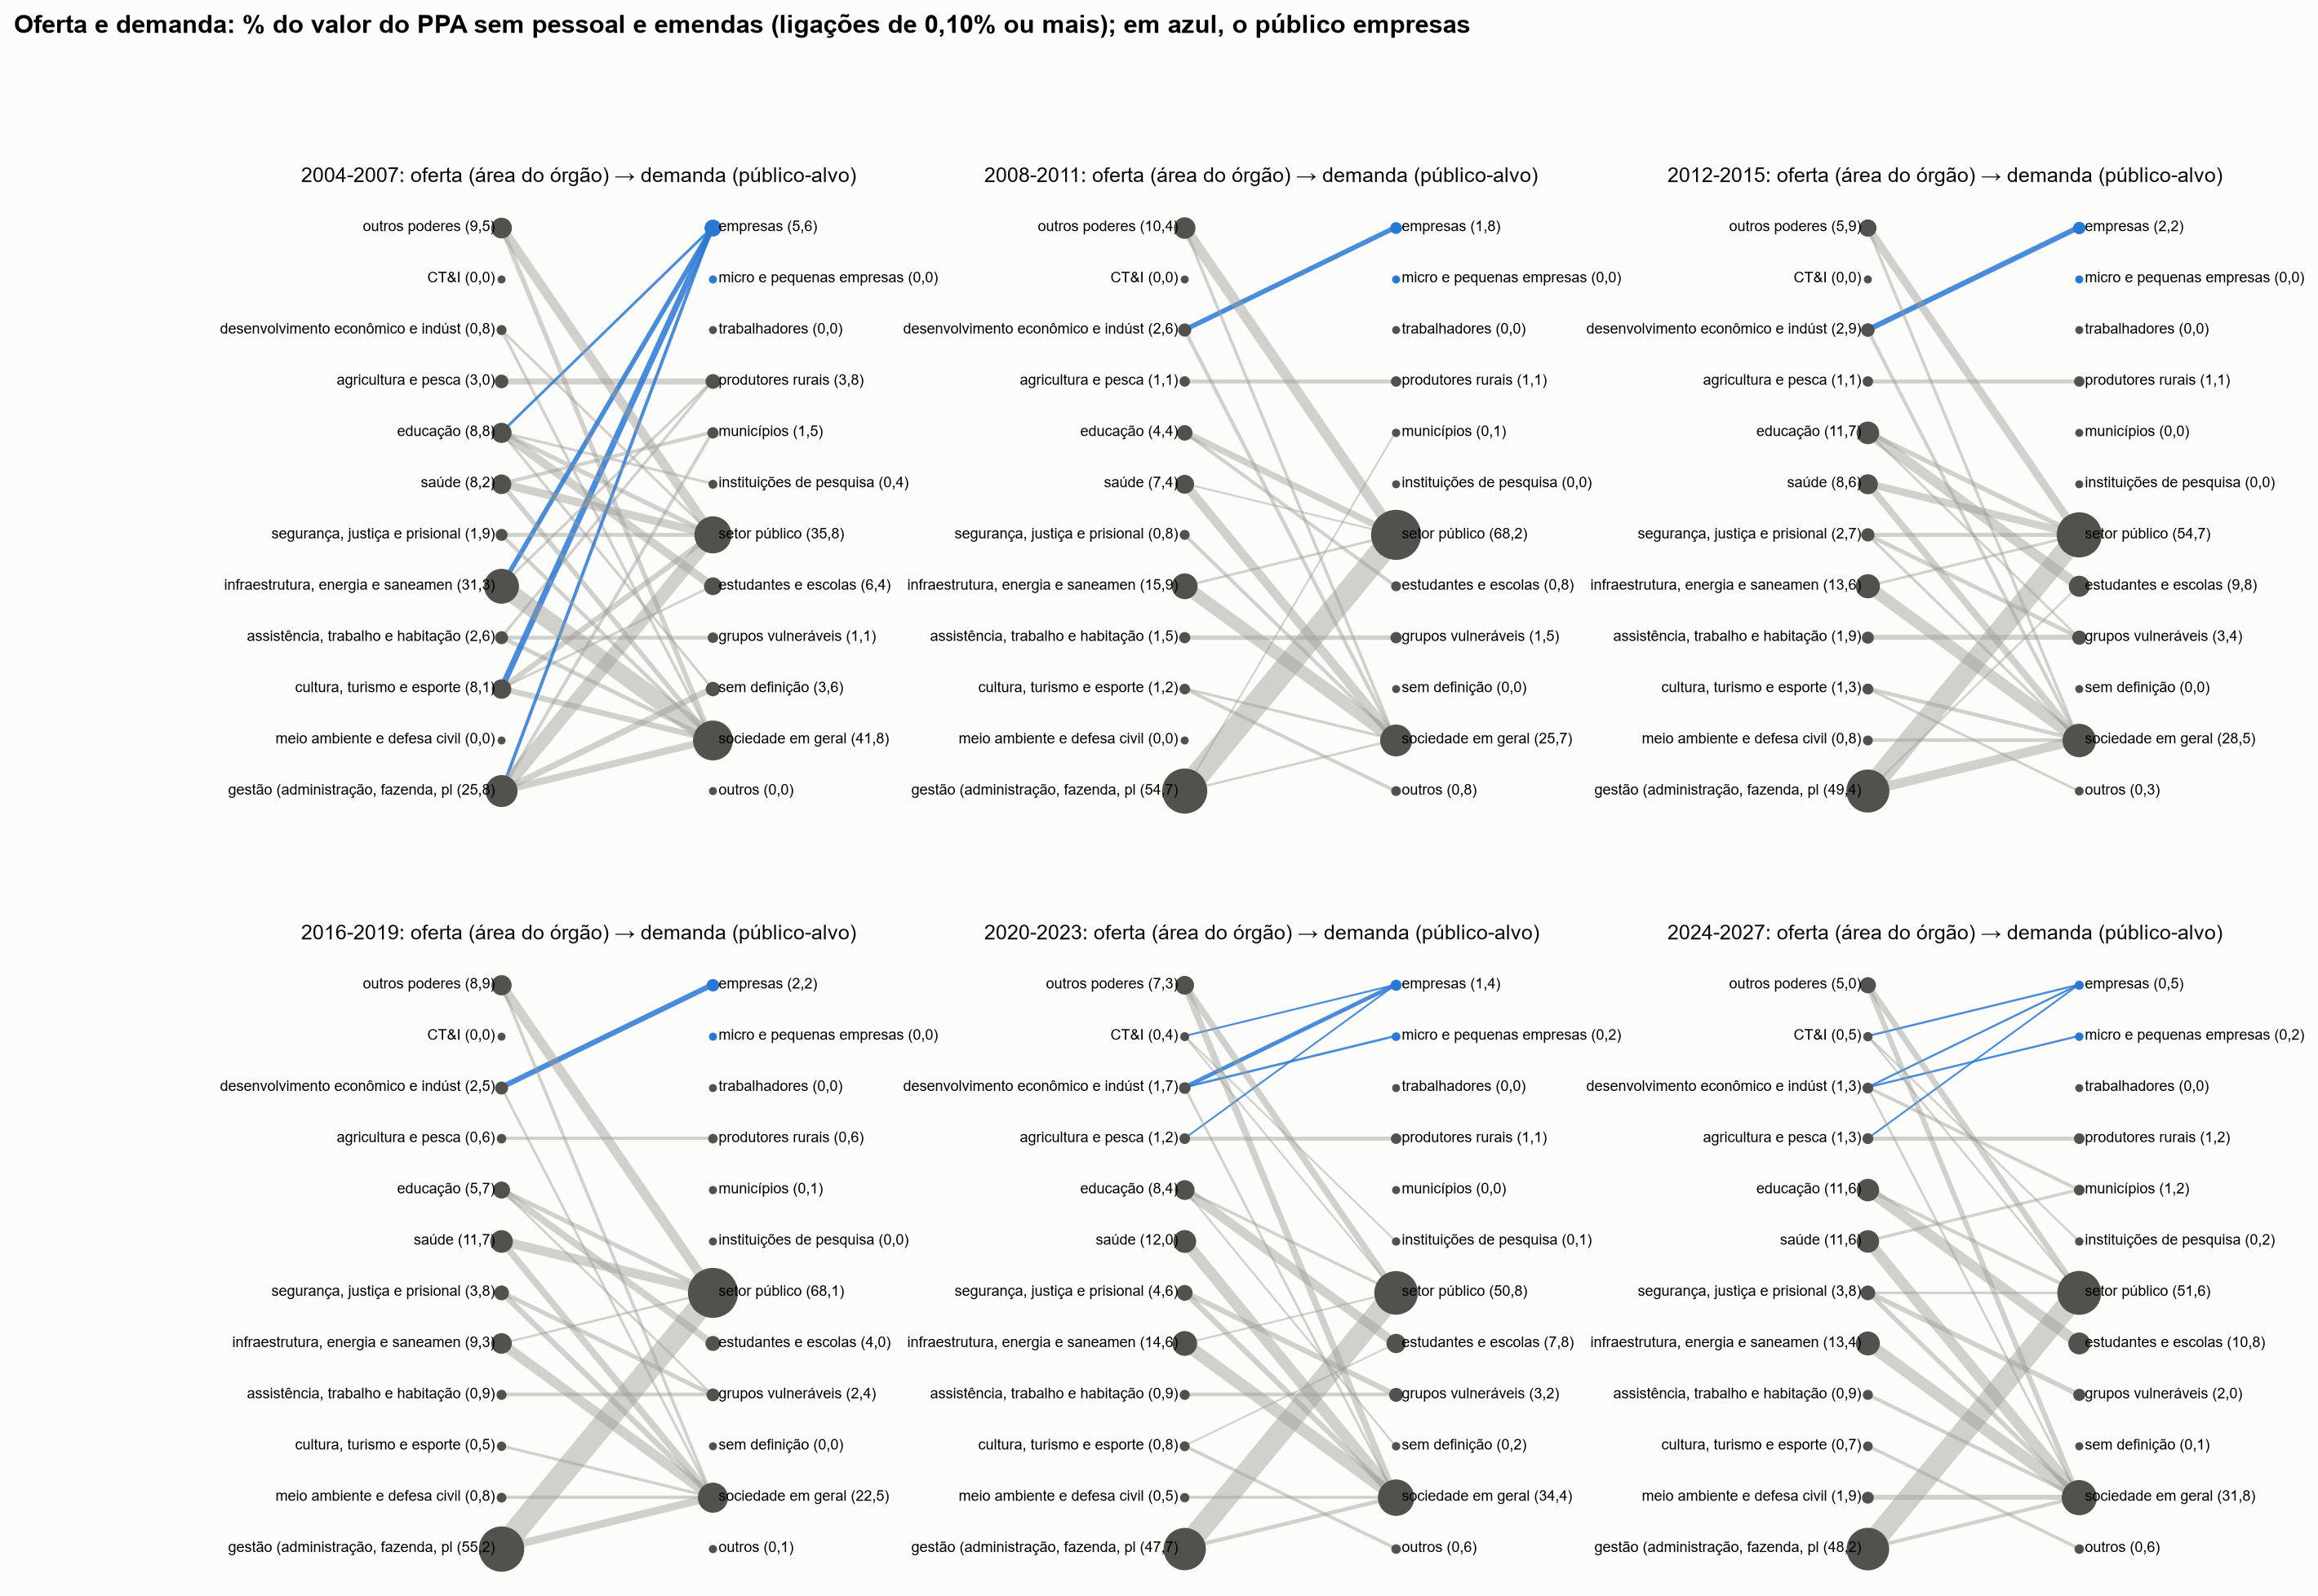

In [9]:
demanda, diversidade, ubiquidade, quem_atende_empresas, sel_od = rede_oferta_demanda(p, s)
display(Markdown("**Demanda: % do valor do PPA por público**"))
tabela(demanda.reset_index(), 2)
fig("rede_oferta_demanda.png", 1100)

In [10]:
display(Markdown("**Quem atende empresas (empresas + micro e pequenas), % do PPA, por área**"))
tabela(quem_atende_empresas.reset_index(), 2)
display(Markdown("**Diversidade da oferta (nº de públicos atendidos por área) e ubiquidade da demanda (nº de áreas que atendem cada público)**"))
tabela(diversidade.reset_index(), 0)
tabela(ubiquidade.reset_index(), 0)
display(Markdown("**Programas selecionados: órgão, público declarado, categoria e % do PPA**"))
with pd.option_context("display.max_colwidth", None):
    tabela(sel_od, 2)

**Quem atende empresas (empresas + micro e pequenas), % do PPA, por área**

area,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
CT&I,"0,00","0,00","0,00","0,00","0,13","0,17"
agricultura e pesca,"0,03","0,00","0,00","0,00","0,10","0,11"
"cultura, turismo e esporte","2,92","0,00","0,00","0,00","0,00","0,00"
desenvolvimento econômico e indústria,"0,00","1,78","2,21","2,21","1,42","0,34"
educação,"0,37","0,00","0,00","0,00","0,00","0,00"
"gestão (administração, fazenda, planejamento, governo)","0,65","0,00","0,01","0,00","0,00","0,00"
"infraestrutura, energia e saneamento","1,66","0,00","0,00","0,00","0,00","0,00"
total,"5,63","1,78","2,22","2,22","1,65","0,63"


**Diversidade da oferta (nº de públicos atendidos por área) e ubiquidade da demanda (nº de áreas que atendem cada público)**

area,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
CT&I,0,0,0,0,3,3
agricultura e pesca,3,1,1,1,2,2
"assistência, trabalho e habitação",4,2,1,1,1,1
"cultura, turismo e esporte",4,2,2,2,3,3
desenvolvimento econômico e indústria,3,2,3,3,4,5
educação,6,4,4,5,4,3
"gestão (administração, fazenda, planejamento, governo)",7,4,5,3,4,3
"infraestrutura, energia e saneamento",3,2,2,2,2,2
meio ambiente e defesa civil,0,0,1,1,2,1
outros poderes,2,2,2,2,3,3


categoria,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
empresas,4,1,2,2,3,3
estudantes e escolas,3,2,2,1,3,2
grupos vulneráveis,3,3,3,3,4,3
instituições de pesquisa,1,0,0,0,1,1
micro e pequenas empresas,1,0,1,1,1,1
municípios,3,1,0,1,1,2
outros,0,1,1,1,2,1
produtores rurais,4,1,1,1,1,1
sem definição,2,0,1,0,2,2
setor público,8,7,6,6,5,6


**Programas selecionados: órgão, público declarado, categoria e % do PPA**

periodo,codigo,orgao,publico_alvo,categoria,pct_ppa
2004-2007,0230,Secretaria de Estado da Agricultura e Desenvolvimento Rural,"Agricultores, Aqüicultores , Pescadores, Famílias",produtores rurais,"0,26"
2004-2007,0410,"Secretaria de Estado da Educação, Ciência e Tecnologia","Órgão Central, Gerências Regionais e Unidades Esco",setor público,"0,08"
2004-2007,0490,"Secretaria de Estado da Educação, Ciência e Tecnologia","Empresas, Universidades e Administração Pública","empresas, instituições de pesquisa, setor público","1,10"
2004-2007,0510,Secretaria de Estado do Planejamento,"Órgãos da Administração Estadual, Outras Organizaç",setor público,"0,02"
2004-2007,0530,"Secretaria de Estado do Desenvolvimento Social, Trabalho e Renda",Cidadão Catarinense,sociedade em geral,"1,14"
2004-2007,0540,Secretaria de Estado da Fazenda,Empresa Catarinense,empresas,"0,01"
2004-2007,0570,Gabinete do Governador do Estado,Empreendedor Catarinense,empresas,"0,01"
2004-2007,0580,Secretaria de Estado do Planejamento,Empreendedores Catarinenses,empresas,"0,62"
2004-2007,0970,Secretaria de Estado do Planejamento,Municípios catarinenses,municípios,"0,64"
2008-2011,0200,Secretaria de Estado do Desenvolvimento Econômico Sustentável,Empreendedores,empresas,"1,34"


**Leitura:** pelo valor, o PPA se dirige ao **setor público** (36% a 68%, inclui dívida e manutenção da máquina) e à **sociedade em geral** (23% a 42%). O público **empresas** recebe 5,6% em 2004-2007 (puxado por programas fora da lista: 0508 Gerar Investimentos, 0695 Gás Natural, 0710 Prodetur, 0675 aeroportos), 1,8% a 2,2% de 2008 a 2019, 1,4% em 2020-2023 e **0,45% em 2024-2027** (0,63% somando micro e pequenas). Nos programas selecionados, o valor dirigido a empresas cai de 2,2% do PPA (2012-2019) para 0,42% em 2024-2027, quando o **maior público declarado da política industrial passa a ser municípios** (0,67% do PPA, pelo 0200, cujo público é "Municípios atendidos"). Pelo lado da oferta, a área de desenvolvimento econômico atende mais tipos de público com o tempo (de 2 para 5 categorias), e empresas passam a ser atendidas por 3 áreas (desenvolvimento econômico, CT&I e agricultura). Ressalvas: o público-alvo é o declarado no programa, cortado em 50 caracteres no PDF, e os valores são orçados e nominais.

## 4. Genealogia dos programas

Um programa B é **filho** de um programa A do PPA anterior se herda de A pelo menos **20%** do valor das subações (mesmo código de 6 dígitos **e** nome parecido, similaridade de 0,6 ou mais) **ou** 20% dos lemas (frases com similaridade de 0,9 ou mais). Eventos: **novo** (sem pai), **um pai**, **fusão** (2 ou mais pais); do lado do PPA anterior, **extinto** (sem filho) e **cisão** (2 ou mais filhos). **Troca de dono:** o órgão do pai principal é outro (regra de sobreposição de palavras dos nomes, que trata renomeação como o mesmo dono).

Atenção: de 2004-2007 para 2008-2011 os códigos de subação foram **renumerados** (só 1% dos códigos repetidos tem nome parecido). Nessa transição só existe herança de texto, e os textos de 2004-2007 são curtos; os "novos" de 2008-2011 são em parte artefato.

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\rede_genealogia.png


**PPA inteiro**

transição,programas novos (%),um pai (%),fusão (%),extintos no PPA anterior (%),cisão no PPA anterior (%),troca de dono (% dos com pai),programas,governo
2004-2007 → 2008-2011,"61,5","38,5","0,0","81,4","0,8","40,0",65,reeleição [verificar]
2008-2011 → 2012-2015,"34,1","60,0","5,9","24,6","10,8","16,1",85,troca [verificar]
2012-2015 → 2016-2019,"6,9","80,5","12,6","10,6","10,6","1,2",87,reeleição [verificar]
2016-2019 → 2020-2023,"29,5","54,5","15,9","35,6","11,5","33,9",88,troca [verificar]
2020-2023 → 2024-2027,"5,8","87,2","7,0","12,5","6,8","9,9",86,troca [verificar]


**Programas selecionados** (novo/um pai/fusão sobre os selecionados do PPA de chegada; extinto/cisão sobre os do PPA de partida)

transição,programas novos (%),um pai (%),fusão (%),extintos no PPA anterior (%),cisão no PPA anterior (%),troca de dono (% dos com pai),programas
2004-2007 → 2008-2011,"50,0","50,0","0,0","100,0","0,0","100,0",4
2008-2011 → 2012-2015,"37,5","62,5","0,0","0,0","25,0","0,0",8
2012-2015 → 2016-2019,"14,3","85,7","0,0","12,5","0,0","0,0",7
2016-2019 → 2020-2023,"28,6","57,1","14,3","28,6","14,3","60,0",7
2020-2023 → 2024-2027,"28,6","71,4","0,0","42,9","14,3","60,0",7


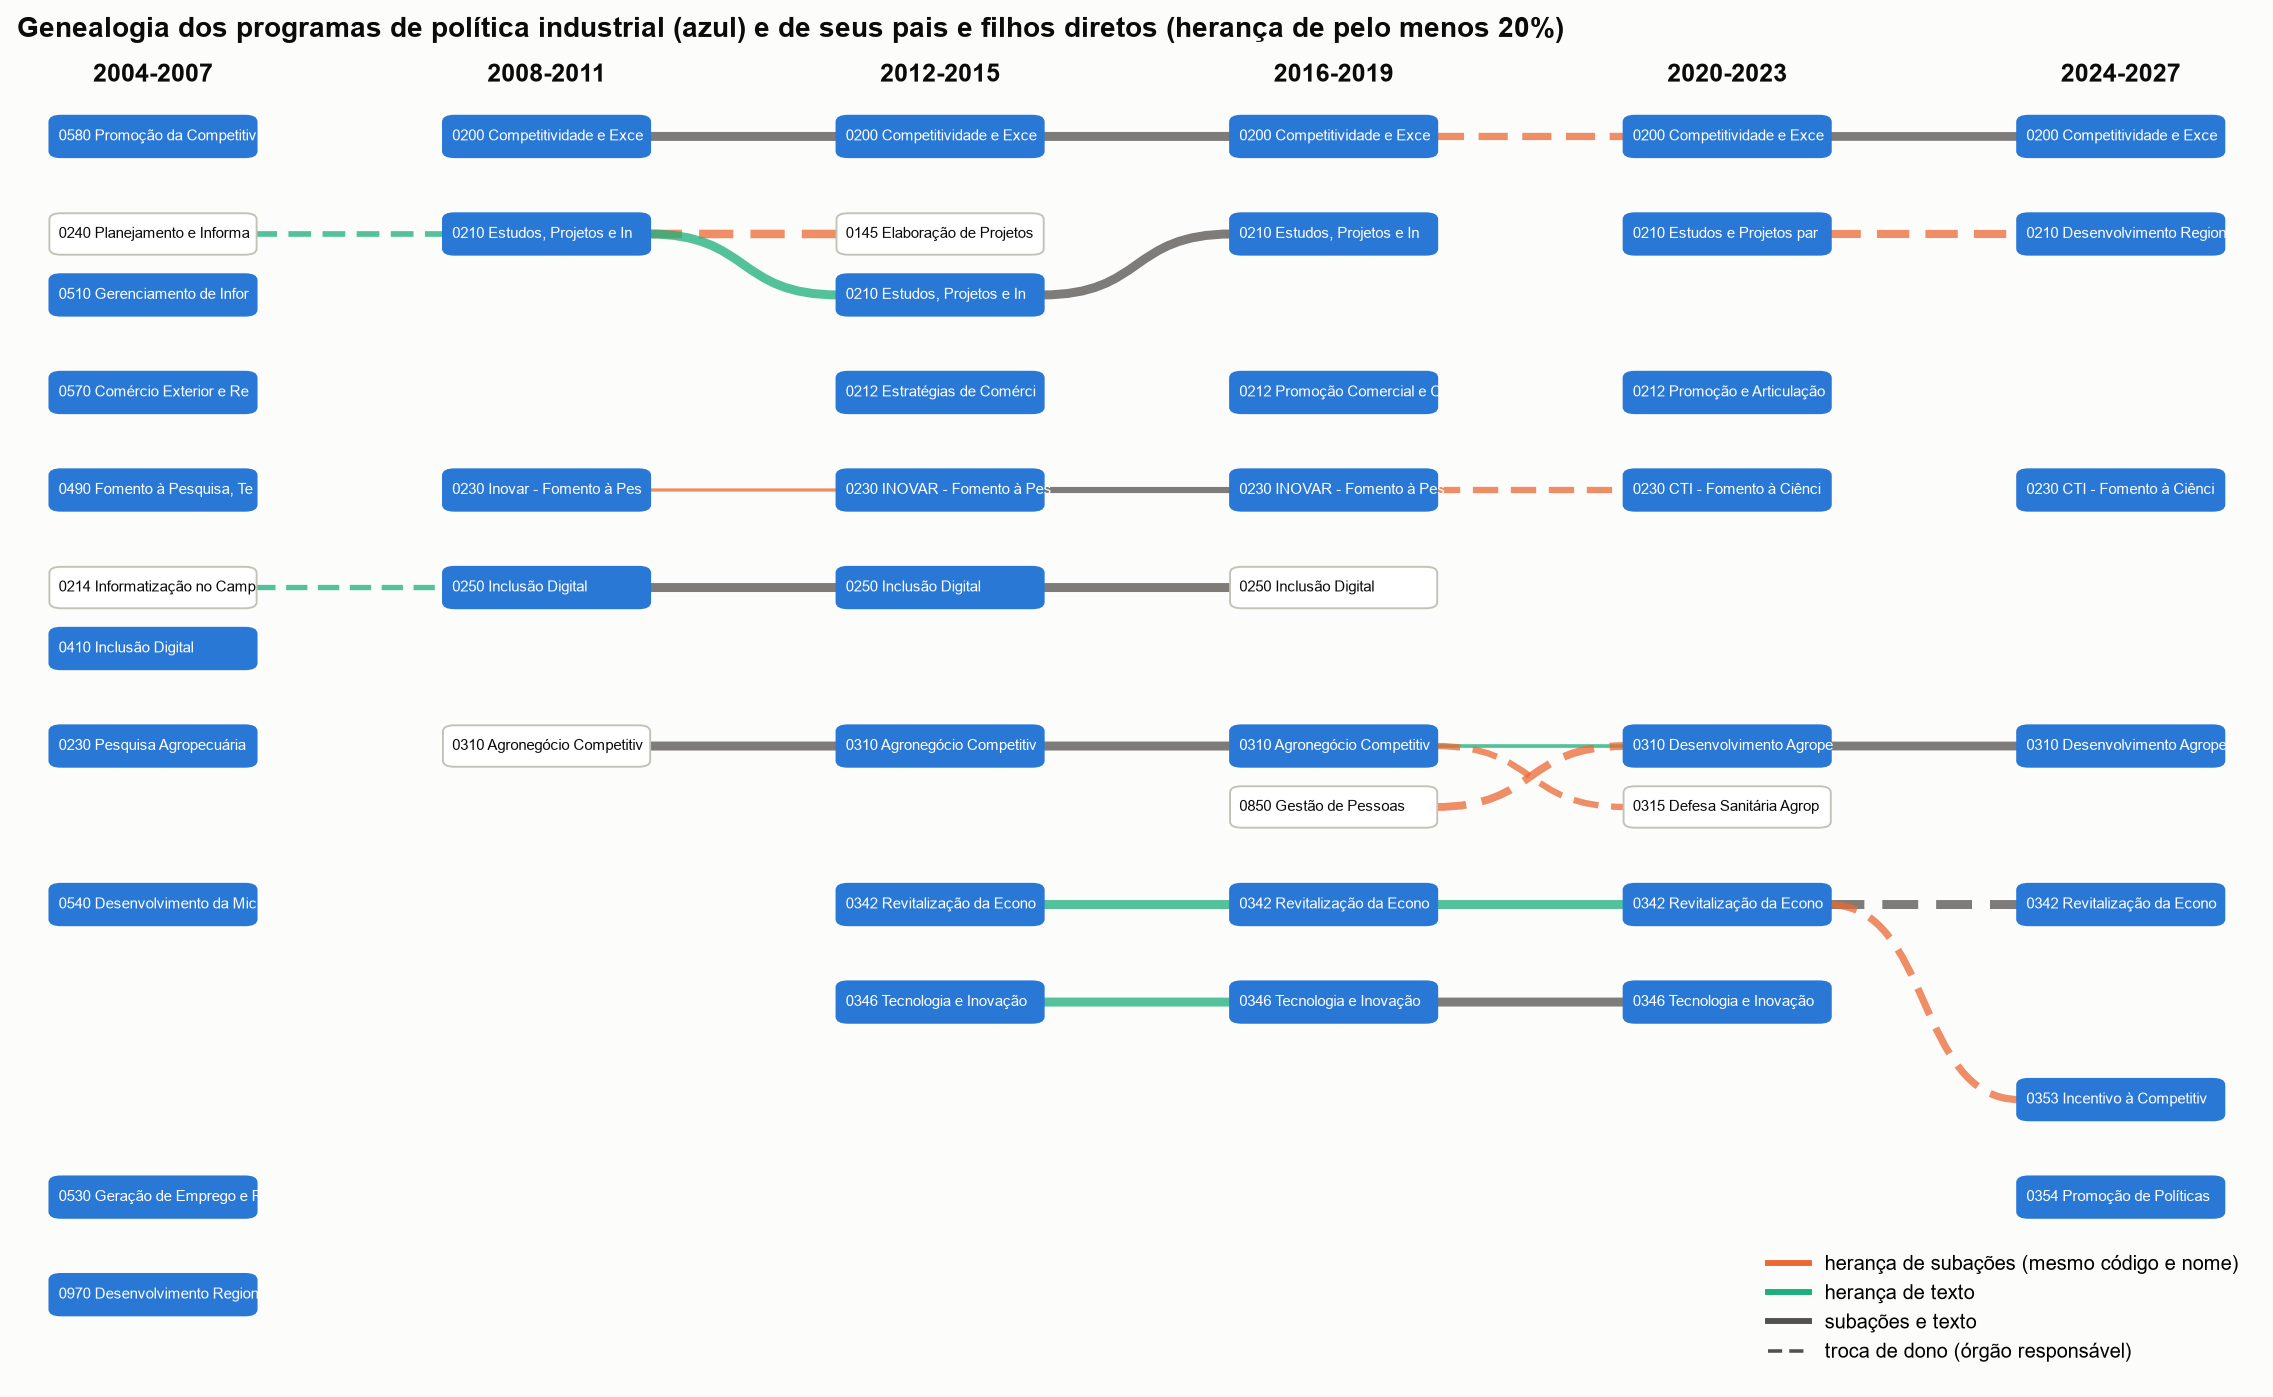

In [11]:
gen_inteiro, gen_sel, eventos, linhagem = genealogia(p, s, f)
display(Markdown("**PPA inteiro**"))
tabela(gen_inteiro.assign(governo=gen_inteiro["transição"].map({
    "2004-2007 → 2008-2011": "reeleição [verificar]", "2008-2011 → 2012-2015": "troca [verificar]",
    "2012-2015 → 2016-2019": "reeleição [verificar]", "2016-2019 → 2020-2023": "troca [verificar]",
    "2020-2023 → 2024-2027": "troca [verificar]"})), 1)
display(Markdown("**Programas selecionados** (novo/um pai/fusão sobre os selecionados do PPA de chegada; extinto/cisão sobre os do PPA de partida)"))
tabela(gen_sel, 1)
fig("rede_genealogia.png", 1100)

In [12]:
display(Markdown("**Eventos dos programas selecionados**"))
ev = eventos[eventos.selecionado == 1].drop(columns=["selecionado"])
tabela(ev.assign(nome=ev.nome.str[:55]), 0)
display(Markdown("**Ligações da linhagem da política industrial (pais e filhos diretos)**"))
tabela(linhagem.assign(nome_origem=linhagem.nome_origem.str[:40], nome=linhagem.nome.str[:40]), 2)

**Eventos dos programas selecionados**

periodo,codigo,nome,evento,pai principal,mesmo código do pai,mesmo dono do pai,pais
2008-2011,0200,Competitividade e Excelência Econômica,novo,nan,None,None,
2008-2011,0210,"Estudos, Projetos e Informações Estratégicas",um pai,0240,None,False,0240 (57%)
2008-2011,0230,Inovar - Fomento à Pesquisa ao Desenvolvimento e à Inov,novo,nan,None,None,
2008-2011,0250,Inclusão Digital,um pai,0214,None,False,0214 (52%)
2012-2015,0200,Competitividade e Excelência Econômica,um pai,0200,True,True,0200 (100%)
2012-2015,0210,"Estudos, Projetos e Informações Estratégicas",um pai,0210,True,True,0210 (100%)
2012-2015,0212,Estratégias de Comércio Exterior e Relações Internacion,novo,nan,None,None,
2012-2015,0230,"INOVAR - Fomento à Pesquisa, ao Desenvolvimento e à Ino",um pai,0230,True,True,0230 (24%)
2012-2015,0250,Inclusão Digital,um pai,0250,True,True,0250 (100%)
2012-2015,0310,Agronegócio Competitivo,um pai,0310,True,True,0310 (100%)


**Ligações da linhagem da política industrial (pais e filhos diretos)**

periodo_origem,origem,nome_origem,periodo,codigo,nome,w_sub,w_txt,mesmo_dono
2004-2007,0240,Planejamento e Informações Estratégicas,2008-2011,0210,"Estudos, Projetos e Informações Estratég","0,00","0,57",False
2004-2007,0214,Informatização no Campo e na Pesca - Bei,2008-2011,0250,Inclusão Digital,"0,00","0,52",False
2008-2011,0210,"Estudos, Projetos e Informações Estratég",2012-2015,0145,Elaboração de Projetos e Estudos de Infr,"0,94","0,00",False
2008-2011,0200,Competitividade e Excelência Econômica,2012-2015,0200,Competitividade e Excelência Econômica,"0,99","1,00",True
2008-2011,0210,"Estudos, Projetos e Informações Estratég",2012-2015,0210,"Estudos, Projetos e Informações Estratég","0,00","1,00",True
2008-2011,0230,Inovar - Fomento à Pesquisa ao Desenvolv,2012-2015,0230,"INOVAR - Fomento à Pesquisa, ao Desenvol","0,24","0,00",True
2008-2011,0250,Inclusão Digital,2012-2015,0250,Inclusão Digital,"0,59","1,00",True
2008-2011,0310,Agronegócio Competitivo,2012-2015,0310,Agronegócio Competitivo,"0,33","1,00",True
2012-2015,0200,Competitividade e Excelência Econômica,2016-2019,0200,Competitividade e Excelência Econômica,"0,93","1,00",True
2012-2015,0210,"Estudos, Projetos e Informações Estratég",2016-2019,0210,"Estudos, Projetos e Informações Estratég","0,96","1,00",True


**Leitura:** no PPA inteiro, a passagem de 2015 (reeleição [verificar]) quase não mexe na estrutura: 7% de programas novos e 1% de troca de dono. A de 2019 (troca [verificar]) é a maior reorganização desde 2011: 30% de programas novos, 36% dos programas anteriores sem sucessor e 34% de troca de dono. A de 2023 (troca [verificar]) é pequena no plano (6% novos, 10% de troca de dono), mas **grande na política industrial**: 3 dos 7 programas selecionados de 2020-2023 ficam sem sucessor (0212, 0230, 0346); o 0230 e o 0354 nascem sem pai; o **0353 nasce de uma cisão do 0342 PREC** (77% do valor vem dele, inclusive o microcrédito Juro Zero); e 3 dos 5 selecionados com pai trocam de dono. Outros movimentos que a rede mostra: o 0200 passa ao BADESC em 2020 mantendo as subações (78% do valor) e **reescrevendo todo o texto**; o 0310 de 2020-2023 é a **fusão da folha da EPAGRI** (0850 Gestão de Pessoas, 85% do valor) com o 0310 antigo; em 2012 o grosso das subações do 0210 vai para o 0145 (projetos de infraestrutura).

## 5. Síntese

- **Competitividade troca de vizinhança:** do vocabulário de base tecnológica e produção (2004-2015) para o de empresa e economia (2016-2027), e se afasta de inovação.
- **Política industrial coesa no discurso, dispersa na ação:** os selecionados formam um bloco pelo texto em todo o período recente, mas deixam de formar bloco pelas subações a partir de 2020; o que os programas dizem e o que fazem se correlaciona pouco.
- **O público empresa perde espaço:** de 2,2% do PPA (2012-2019) para 0,45% (2024-2027); na política industrial de 2024-2027, municípios recebem mais que empresas.
- **2023 reorganiza a política industrial, não o plano:** o plano copia texto e estrutura, mas a política industrial ganha programas sem pai (0230, 0354), uma cisão (0342 → 0353) e troca de dono, junto com as novas secretarias [verificar datas].

**Limitações:** comunidades de termos instáveis (só vizinhanças são interpretadas); público-alvo declarado e cortado em 50 caracteres; valores orçados e nominais, sem execução; 2004 → 2008 sem herança de subações; regras com aprovação preliminar.

**Regras preliminares a revisar** (todas em `scripts/redes_regras.py`; detalhes em `docs/decisoes.md`): limiares da rede de termos (4 frases, 2 coocorrências); palavras de formato (> 20% dos programas); 3 vizinhos e cosseno mínimo de 0,10; categorias novas de público e a regra de precedência; exceção da comunicação institucional; herança de 20%; subação herdada com código igual e nome parecido (0,6); regra de "mesmo dono".